# 📏 Forecasting Weekly Product Demand — Part 8: Are the Gains Real? Statistical Tests

**Goal of this notebook:** check with statistics how much the results from Parts 4 and 7 can be trusted. A single test score depends on which products and which weeks happened to be in the test, so we ask four questions:

1. **How sure is the test WAPE of 52.9%?** → a **bootstrap confidence interval**
2. **Is the LightGBM model really better than the moving average?**
3. **Is the Part 7 model (with order features) really better than the Part 4 model?**
4. **Where does the Part 7 gain come from:** the bulk-order weeks it was aimed at, or normal weeks?

For questions 2 and 3 we use two different tests, because there are two kinds of luck:
- **Luck in the products:** would the gain hold for a different set of similar products? → **paired bootstrap** over products
- **Luck in the weeks:** would the gain hold in other weeks? → **Diebold-Mariano test** over time

The functions are in `src/stats.py`. No model is changed in this notebook.

## 1. Setup and Forecasts

We rebuild the forecasts of three models on the **4 folds** used in Parts 3–7, with exactly the same settings (tuned parameters from Part 4, random seed 42):
- **MA13**: the 13-week moving average, the best simple baseline from Part 3
- **Part 4**: LightGBM with the Part 4 features
- **Part 7**: LightGBM with the Part 4 features + order features (the model the app uses)

The weekly order counts are taken from the saved app bundle, so this notebook does not need the full SQL database. The p10 and p90 models of the Part 7 model are also trained on the test fold, for the coverage interval.

In [1]:
import sys
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import lightgbm as lgb

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.evaluation import evaluate, moving_average_forecast
from src.features import (FEATURES, ORDER_FEATURES, CATEGORICAL, HORIZON,
                          make_features, build_training_set, cap_outliers, outlier_fence)
from src.stats import diebold_mariano, bootstrap_ratio, bootstrap_wape, percentile_ci

bundle_v1 = joblib.load(ROOT / "models" / "forecast_bundle_v1.pkl")   # Part 4 model
bundle_v2 = joblib.load(ROOT / "models" / "forecast_bundle.pkl")      # Part 7 model (used by the app)
Y = bundle_v1["history"]          # week x product units
O = bundle_v2["orders"]           # week x product orders (built with SQL in Part 7)
PARAMS = bundle_v1["params"]      # tuned settings from Part 4

FOLD_ENDS = {"val 1": 71, "val 2": 79, "val 3": 87, "test": 95}
LIGHTGBM = {"Part 4": FEATURES, "Part 7": FEATURES + ORDER_FEATURES}

def fit_predict(train_rows, pred_rows, features, alpha=0.5):
    """Train one LightGBM model and return its forecasts (weeks x products)."""
    params = PARAMS | {"random_state": 42}
    if alpha != 0.5:
        params = params | {"objective": "quantile", "alpha": alpha}
    m = lgb.LGBMRegressor(**params)
    m.fit(train_rows[features], train_rows["y"],
          sample_weight=train_rows["scale"], categorical_feature=CATEGORICAL)
    p = m.predict(pred_rows[features]) * pred_rows["scale"].to_numpy()
    return np.clip(p, 0, None).reshape(HORIZON, -1)

actual, fc = {}, {}
for fold, e in FOLD_ENDS.items():
    train_rows, fence = build_training_set(Y, e, orders=O)
    pred_rows = make_features(cap_outliers(Y.iloc[: e + 1], fence), e, orders=O)
    actual[fold] = Y.iloc[e + 1 : e + 1 + HORIZON].to_numpy()
    fc[fold] = {"MA13": moving_average_forecast(Y, e)}
    fc[fold] |= {name: fit_predict(train_rows, pred_rows, feats) for name, feats in LIGHTGBM.items()}
    if fold == "test":
        p10 = fit_predict(train_rows, pred_rows, LIGHTGBM["Part 7"], alpha=0.1)
        p90 = fit_predict(train_rows, pred_rows, LIGHTGBM["Part 7"], alpha=0.9)

wape = pd.DataFrame({
    fold: {name: evaluate(actual[fold], f, Y.iloc[: FOLD_ENDS[fold] + 1])["WAPE"] for name, f in fc[fold].items()}
    for fold in FOLD_ENDS
}).T
print("WAPE (%) per fold:")
(wape * 100).round(2)

WAPE (%) per fold:


,MA13,Part 4,Part 7
val 1,54.17,54.06,53.61
val 2,59.59,54.96,54.43
val 3,57.42,52.62,52.59
test,57.94,53.42,52.88


📌 **Reading this:** the rebuilt forecasts give the same test WAPE as before: **57.9%** for the moving average (Part 3), **53.4%** for the Part 4 model and **52.9%** for the Part 7 model. So everything below tests exactly the numbers reported in the README.

## 2. How Sure Is the Test WAPE? Bootstrap Confidence Intervals

The test WAPE comes from **100 products**. With a different set of 100 similar products, the score would be a bit different. The **bootstrap** estimates how much:

1. Draw 100 products **with replacement** from the 100 test products (some appear twice, some not at all). Each product keeps all its 8 test weeks.
2. Compute WAPE on this new sample.
3. Repeat **10,000 times**. The middle 95% of the 10,000 WAPE values is the **95% confidence interval**.

The same is done for the p10–p90 coverage of the Part 7 model (target: 80%).

In [2]:
A = actual["test"]
boot = bootstrap_wape(A, fc["test"], n_boot=10_000, seed=0)

ci = pd.DataFrame({
    name: {"test WAPE": wape.loc["test", name],
           "95% CI low": percentile_ci(boot[name])[0],
           "95% CI high": percentile_ci(boot[name])[1]}
    for name in boot
}).T
print("WAPE (%) on the test fold, with bootstrap 95% confidence intervals:")
display((ci * 100).round(1))

# p10-p90 coverage of the Part 7 model: share of product-weeks inside the range
low_q, _, high_q = np.sort(np.stack([p10, fc["test"]["Part 7"], p90]), axis=0)
inside = ((A >= low_q) & (A <= high_q)).sum(axis=0)                  # weeks inside, per product
cov_boot = bootstrap_ratio({"coverage": inside}, np.full(A.shape[1], HORIZON), seed=0)["coverage"]
low, high = percentile_ci(cov_boot)
print(f"p10-p90 coverage (Part 7): {inside.sum() / A.size:.1%}  "
      f"(95% CI {low:.1%} to {high:.1%}, target 80%)")

WAPE (%) on the test fold, with bootstrap 95% confidence intervals:


,test WAPE,95% CI low,95% CI high
MA13,57.9,52.2,64.0
Part 4,53.4,48.6,58.3
Part 7,52.9,48.0,57.7


p10-p90 coverage (Part 7): 81.5%  (95% CI 77.6% to 85.1%, target 80%)


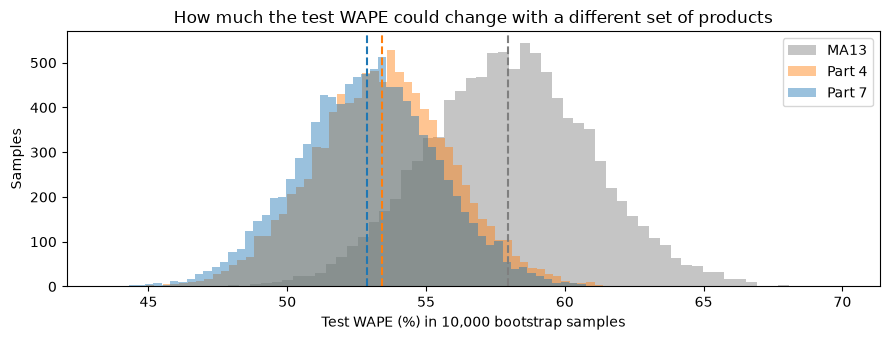

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.5))
for name, color in zip(boot, ["tab:grey", "tab:orange", "tab:blue"]):
    ax.hist(boot[name] * 100, bins=60, alpha=0.45, color=color, label=name)
    ax.axvline(wape.loc["test", name] * 100, color=color, linestyle="--")
ax.set_xlabel("Test WAPE (%) in 10,000 bootstrap samples")
ax.set_ylabel("Samples")
ax.set_title("How much the test WAPE could change with a different set of products")
ax.legend()
plt.tight_layout()
plt.show()

📌 **Reading this:**
- The Part 7 model's test WAPE is **52.9%, with a 95% confidence interval of about 48% to 58%**. The interval is wide because a few products with very large, noisy demand move the score a lot.
- The p10–p90 coverage interval **contains the 80% target**, so the forecast ranges are as wide as they should be.
- The three intervals **overlap a lot**, but this does **not** mean the models are equal. Products that are hard to forecast are hard for every model, so all three scores move up and down together. To compare two models, we must look at the **difference on the same products** (next section).

## 3. Is One Model Really Better? Paired Bootstrap

Same bootstrap, but in every sample we compute the WAPE of **two models on the same resampled products** and take the difference. If the difference stays below zero in (almost) all 10,000 samples, the gain does not depend on which products happened to be in the test.

In [4]:
pairs = [("Part 7", "MA13"), ("Part 4", "MA13"), ("Part 7", "Part 4")]

rows = []
for a, b in pairs:
    d = boot[a] - boot[b]
    low, high = percentile_ci(d)
    rows.append({"comparison": f"{a} − {b}",
                 "WAPE difference (pp)": (wape.loc["test", a] - wape.loc["test", b]) * 100,
                 "95% CI low (pp)": low * 100,
                 "95% CI high (pp)": high * 100,
                 "samples where the first is better": (d < 0).mean()})

paired = pd.DataFrame(rows).set_index("comparison")
paired.round(3)

,WAPE difference (pp),95% CI low (pp),95% CI high (pp),samples where the first is better
comparison,,,,
Part 7 − MA13,-5.066,-7.705,-2.974,1.00
Part 4 − MA13,-4.521,-7.089,-2.439,1.00
Part 7 − Part 4,-0.545,-1.019,-0.086,0.99


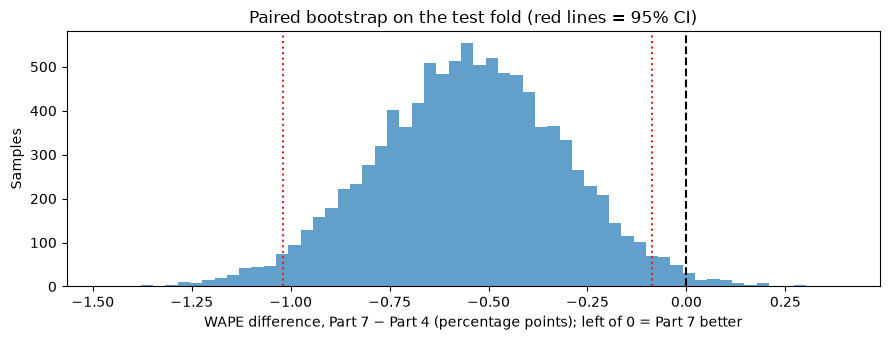

In [5]:
d = (boot["Part 7"] - boot["Part 4"]) * 100

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(d, bins=60, color="tab:blue", alpha=0.7)
ax.axvline(0, color="black", linestyle="--")
for x in percentile_ci(d):
    ax.axvline(x, color="tab:red", linestyle=":")
ax.set_xlabel("WAPE difference, Part 7 − Part 4 (percentage points); left of 0 = Part 7 better")
ax.set_ylabel("Samples")
ax.set_title("Paired bootstrap on the test fold (red lines = 95% CI)")
plt.tight_layout()
plt.show()

📌 **Reading this:**
- **LightGBM vs moving average:** both LightGBM models are better in **all 10,000 samples**, by about **4–5 percentage points** (95% CI roughly −7.7 to −2.4 points). This gain is clearly real.
- **Part 7 vs Part 4:** the gain is small, **−0.5 points (95% CI about −1.0 to −0.1)**, but Part 7 is better in **99% of the samples**. So across products, the order features help consistently.
- This test only resamples **products**. All 100 products share the same 8 test weeks, so if those weeks were unusual (for example, one strong Christmas season), the bootstrap cannot see it. That is what the Diebold-Mariano test checks.

## 4. Over Time: the Diebold-Mariano Test

The **Diebold-Mariano (DM) test** is the standard test for "do two forecasts have the same accuracy?". It looks at the **loss difference** between two forecasts in each week and asks whether its average is different from zero.

How it is set up here:
- **Loss per week** = mean absolute error over the 100 products (the same error as MAE / WAPE).
- **Weeks:** the test fold alone has only 8 weeks, which is too few. The 4 folds cover **32 weeks in a row** (25 April – 28 November 2011) without overlap, so we use all 32.
- **Autocorrelation:** within one fold, all 8 weeks are forecast from the same origin, so their errors are related. The test allows correlation up to **7 weeks apart** (horizon − 1), and we also check 3 weeks as a robustness check.
- Small-sample correction of Harvey, Leybourne & Newbold (1997), with a t distribution.

One caution: the 24 validation weeks were used to tune the models and choose the features in Parts 3, 4 and 7, which favours the tuned models a little. Only the 8 test weeks are untouched.

In [6]:
weekly_mae = {name: np.concatenate([np.abs(fc[f][name] - actual[f]).mean(axis=1) for f in FOLD_ENDS])
              for name in fc["test"]}
dm_weeks = Y.index[FOLD_ENDS["val 1"] + 1 : FOLD_ENDS["test"] + 1 + HORIZON]
print(f"{len(dm_weeks)} weeks: {dm_weeks[0]:%d %b %Y} to {dm_weeks[-1]:%d %b %Y}")

rows = []
for a, b in pairs:
    r = diebold_mariano(weekly_mae[a], weekly_mae[b], max_lag=HORIZON - 1)
    r3 = diebold_mariano(weekly_mae[a], weekly_mae[b], max_lag=3)
    rows.append({"comparison": f"{a} − {b}",
                 "mean MAE difference (units)": r["mean_diff"],
                 "weeks where the first is better": int((weekly_mae[a] < weekly_mae[b]).sum()),
                 "DM statistic": r["DM"],
                 "p-value": r["p_value"],
                 "p-value (lag 3)": r3["p_value"]})

dm = pd.DataFrame(rows).set_index("comparison")
dm.round(4)

32 weeks: 25 Apr 2011 to 28 Nov 2011


,mean MAE difference (units),weeks where the first is better,DM statistic,p-value,p-value (lag 3)
comparison,,,,,
Part 7 − MA13,-10.3658,30,-3.3390,0.0022,0.0003
Part 4 − MA13,-9.3510,28,-2.6504,0.0125,0.0014
Part 7 − Part 4,-1.0148,22,-1.8826,0.0692,0.0854


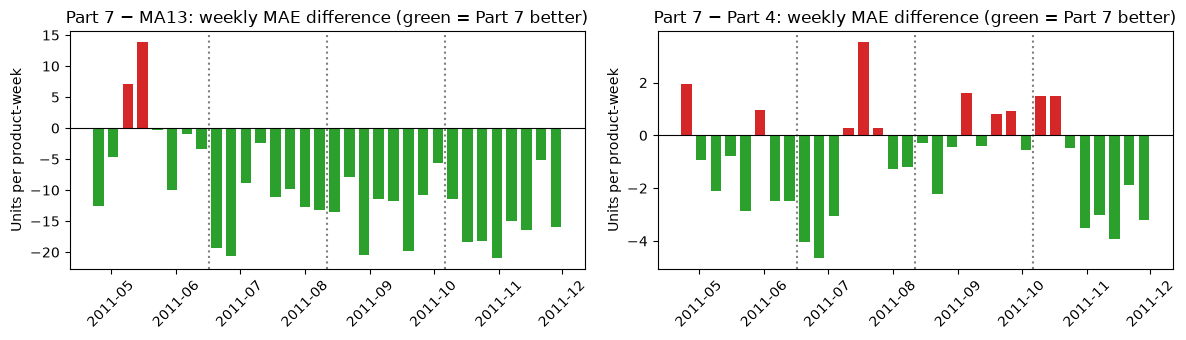

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharex=True)
for ax, (a, b) in zip(axes, [("Part 7", "MA13"), ("Part 7", "Part 4")]):
    diff = weekly_mae[a] - weekly_mae[b]
    ax.bar(dm_weeks, diff, width=5, color=np.where(diff < 0, "tab:green", "tab:red"))
    for e in list(FOLD_ENDS.values())[1:]:
        ax.axvline(Y.index[e] + pd.Timedelta(days=3.5), color="grey", linestyle=":")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(f"{a} − {b}: weekly MAE difference (green = {a} better)")
    ax.set_ylabel("Units per product-week")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

📌 **Reading this:** (dotted lines separate the 4 folds)
- **LightGBM vs moving average: significant.** The Part 7 model has a lower error in **30 of the 32 weeks**, and the DM test gives **p ≈ 0.002** (Part 4 model: p ≈ 0.01). The result holds with 3 lags too.
- **Part 7 vs Part 4: not significant at the 5% level (p ≈ 0.07).** The average gain is about **1 unit per product-week**, and Part 7 wins in **22 of the 32 weeks**, but the other 10 go the other way, and 32 weeks are not enough to rule out luck for such a small gain.
- The two tests agree on the big result and differ on the small one. The order features help **across products** (paired bootstrap), but the gain is **too small to prove over time** with one year of weeks.

## 5. Where Does the Part 7 Gain Come From? Bulk-Order Weeks vs Normal Weeks

The order features were added in Part 7 mainly to target **bulk orders**: one-off weeks where a wholesale customer buys far more than usual. Part 5 found that these weeks are only about 4% of product-weeks but cause about 28% of the error.

Here we split the test-fold error into **bulk-order weeks** (actual units above the product's outlier fence from the training weeks, the same definition as in `evaluate()`) and **normal weeks**, and check where the Part 7 model actually gained.

In [8]:
e = FOLD_ENDS["test"]
bulk = A > outlier_fence(Y.iloc[: e + 1]).to_numpy()      # bulk-order product-weeks
print(f"Bulk-order weeks in the test fold: {bulk.sum()} of {bulk.size} product-weeks ({bulk.mean():.1%}), "
      f"{A[bulk].sum() / A.sum():.1%} of the units sold")

rows = []
for name, f in fc["test"].items():
    err = np.abs(f - A)
    rows.append({"model": name,
                 "error in bulk weeks": err[bulk].sum(),
                 "error in normal weeks": err[~bulk].sum(),
                 "bulk share of error": err[bulk].sum() / err.sum(),
                 "bulk weeks under-forecast by": (A[bulk] - f[bulk]).sum() / A[bulk].sum()})
split = pd.DataFrame(rows).set_index("model")

gain = split.loc["Part 4"] - split.loc["Part 7"]
total = gain["error in bulk weeks"] + gain["error in normal weeks"]
print(f"Part 7 vs Part 4: total error lower by {total:,.0f} units, "
      f"{gain['error in normal weeks']:,.0f} in normal weeks and {gain['error in bulk weeks']:,.0f} in bulk weeks")
split.round(3)

Bulk-order weeks in the test fold: 31 of 800 product-weeks (3.9%), 19.7% of the units sold
Part 7 vs Part 4: total error lower by 1,308 units, 1,201 in normal weeks and 107 in bulk weeks


,error in bulk weeks,error in normal weeks,bulk share of error,bulk weeks under-forecast by
model,,,,
MA13,37797.154,101189.769,0.272,0.801
Part 4,36553.561,91589.431,0.285,0.775
Part 7,36446.935,90388.203,0.287,0.773


📌 **Reading this:**
- Bulk-order weeks are only **31 of 800** test product-weeks, but they hold about 20% of the units and about **28% of the error**, for every model.
- **The Part 7 gain comes almost entirely from normal weeks:** about **1,200 of the 1,300 units** of lower error. In bulk weeks the error is almost unchanged.
- In bulk weeks all models still forecast far too little: the Part 7 forecast is about **77% below** the actual units, so it covers only about a quarter of what was sold.
- So the order features **did not solve the bulk-order problem**. They help as a general signal of how many customers are buying a product lately. A one-off wholesale order cannot be seen in sales history before it happens; forecasting it would need other data, such as advance orders from wholesale customers. In the app, stocking to **p90** covers part of this risk.

## 6. Summary

| Question | Bootstrap (test fold, over products) | Diebold-Mariano (32 weeks, over time) | Conclusion |
|---|---|---|---|
| How sure is the test WAPE of 52.9%? | 95% CI about **48% – 58%** | — | The score depends quite a lot on the product mix |
| Is the p10–p90 range well calibrated? | coverage 81.5%, CI contains 80% | — | Yes |
| LightGBM better than the moving average? | better in 100% of samples, about −4.5 pp | **p ≈ 0.002** | **Yes, clearly** |
| Part 7 better than Part 4? | better in 99% of samples, −0.5 pp | p ≈ 0.07 | **Small gain:** consistent across products, not proven over time |
| Did Part 7 fix bulk orders? | — | — | **No:** the gain is in normal weeks; bulk weeks are still ~77% under-forecast |

**What this means**
- The main claim of the project, **LightGBM beats the classic moving average**, passes both tests.
- The Part 7 improvement is honest but small. It is fair to say "the order features gave a small, consistent improvement", not "a big improvement".
- Bulk orders and the Christmas peak remain the two open problems; both need data that sales history does not contain.
- A single test WAPE is not exact: with different products it could be about ±5 points. That is why every comparison in this project is made **on the same products and weeks**.

**Next steps**
- More years of data would give more weeks for the DM test and a fairer check of small gains.